# 02 · Standing on others' shoulders: pretrained word vectors and an honest comparison

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryammahmoudi1993/LSTM_emotion_recognition/blob/main/notebooks/02_pretrained_vectors_and_baselines.ipynb)

**After this notebook you will be able to** explain what "pretrained" means, start an LSTM from pretrained word vectors (GloVe),
and compare it fairly with a from-scratch LSTM, a word-counting baseline and a ready-made rule-based tool, using several seeds
and one shared test set.

*Time: about 40 minutes (the training cells take roughly twelve minutes on a laptop CPU in total).
Prerequisite: notebook 01.*

## 1 · The big question

In notebook 01 the LSTM had to learn what the word "great" means from only 20,000 reviews, starting from random numbers.
A person who reads reviews has read millions of pages before. **What if the model also started with that knowledge?**
This idea is called **transfer learning**: reuse what was learned on a huge task for a smaller one.

**An important note on what we could and could not do.** The most famous form of transfer learning for text is a large
*pretrained language model* (a Transformer such as BERT) that is fine-tuned for sentiment. In the environment where this
notebook was written, the website that hosts such models (huggingface.co) **refused the connection**, so
**no Transformer could be downloaded or tested here**, and this notebook contains no result for one. (If you have access,
trying a ready-made sentiment model from that hub on the same reviews is the natural next experiment.)
What we *can* do with the files that were reachable is the oldest and simplest form of reuse, **pretrained word vectors**,
and compare it with a ready-made rule-based sentiment tool. Neither of them is a pretrained language model; we will not call them one.

## 2 · Intuition first: a student who already read a library

Two students must learn to judge film reviews. The first has never read anything and starts from page one of the course.
The second has first read a large library and knows that "excellent" and "superb" are close in meaning and that "awful" is their opposite;
she only has to learn how those meanings relate to a review's verdict.

**GloVe** (Pennington, Socher and Manning, 2014) is such a library, boiled down to numbers: for each of 400,000 words it provides 50 coordinates, learned
from about 6 billion words of Wikipedia and newswire text.

**Math (light).** GloVe looks at how often words appear near each other. For two words $i$ and $j$ it wants

$$\mathbf{w}_i \cdot \tilde{\mathbf{w}}_j + b_i + \tilde b_j \approx \log X_{ij}$$

- $X_{ij}$: how many times word $j$ occurs close to word $i$ in the text;
- $\mathbf{w}_i$ and $\tilde{\mathbf{w}}_j$: the coordinate lists (vectors) of the two words, and $\cdot$ is the dot product (multiply position by position and add);
- $b_i$, $\tilde b_j$: one offset per word;
- $\log$: the logarithm, which keeps huge counts manageable.

Words that keep similar company end up with similar vectors. Nobody told GloVe anything about sentiment.

We compare **five** ways to judge a review:

| Name | What it is | Training |
|---|---|---|
| bag of words | counts words, logistic regression | on our 20,000 reviews |
| LSTM from scratch | the LSTM of notebook 01 (random start) | on our 20,000 reviews |
| LSTM + GloVe (frozen) | LSTM whose word vectors are GloVe and are *not* changed | only the LSTM part is trained |
| LSTM + GloVe (fine-tuned) | the same start, but the word vectors may also be adjusted | everything is trained |
| VADER | a hand-made dictionary of word scores plus a few rules (Hutto and Gilbert, 2014) | none |

> **Predict:** which will be best: the fine-tuned GloVe LSTM, the frozen one or the one from scratch? And will the ready-made VADER tool come close?

In [1]:
import os, pathlib, subprocess, sys

# On Google Colab the repository is not there yet, so we download it once.
if "google.colab" in sys.modules and not pathlib.Path("src").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/maryammahmoudi1993/LSTM_emotion_recognition.git"], check=True)
    os.chdir("LSTM_emotion_recognition/notebooks")

sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent))   # lets us import from src/

import time
import numpy as np
import matplotlib.pyplot as plt

from src import imdb_text as it
from src.imdb_text import save_figure

it.set_seed()                      # fixed seed (42): you should get the same numbers as the author
plt.rcParams["figure.dpi"] = 100

In [2]:
(x_train, y_train), (x_val, y_val), (x_test, y_test) = it.load_reviews(n_train=20000)
x_train_pad, x_val_pad, x_test_pad = it.pad(x_train), it.pad(x_val), it.pad(x_test)
mapping = it.word_to_id()
inverse = it.id_to_word(mapping)

glove_path = it.download_glove()                          # about 69 MB, stored by Keras, checksum verified
glove, found = it.glove_matrix(glove_path, mapping)
print(f"\nwords of our 10,000-word dictionary that have a GloVe vector: {found} of {it.VOCAB - 3}")
print("embedding table built from GloVe:", glove.shape, "(10,000 words x 50 coordinates)")


words of our 10,000-word dictionary that have a GloVe vector: 9793 of 9997
embedding table built from GloVe: (10000, 50) (10,000 words x 50 coordinates)


**What to notice.** Almost every word of our dictionary exists in GloVe, so the pretrained table can replace the random one.
The few missing words and the three special symbols get small random numbers. Note that GloVe vectors have 50 coordinates, the from-scratch model of notebook 01 used 32, so the models also differ in size; we keep this in mind when reading the table.
Let us see whether GloVe really groups similar words, using the same four words as in notebook 01.

In [3]:
for word in ["great", "awful", "boring", "excellent"]:
    neighbours = it.cosine_neighbours(glove, mapping, inverse, word)
    print(f"{word:10s}", ", ".join(f"{w} ({s:.2f})" for w, s in neighbours))

great      greatest (0.82), good (0.80), perhaps (0.79), life (0.78), well (0.78), little (0.78)
awful      horrible (0.93), terrible (0.89), dreadful (0.87), unbelievable (0.85), scary (0.83), weird (0.82)
boring     awfully (0.85), pretty (0.82), funny (0.81), incredibly (0.80), silly (0.80), weird (0.79)
excellent  quality (0.86), good (0.81), skill (0.79), skills (0.77), superb (0.77), best (0.77)


**What to notice.** Compare with the neighbour lists of notebook 01, where the vectors were learned from 20,000 reviews only.

- GloVe's lists are more sensible for most of these words: *awful* is near *horrible*, *terrible* and *dreadful*; *excellent* is near *superb*, *best* and *good*.
- They are not about *sentiment*, though: *boring* has *funny*, *silly* and *pretty* as neighbours, words that often appear in the same kind of sentences as *boring* but do not mean the same, and *great* is close to *greatest*, *good*, *life* and *well*. GloVe tells which words keep similar company, and that is not always the same as having the same meaning or the same sentiment.

So the pretrained vectors carry general knowledge about words, but the fine-tuning step has to teach the model what matters for *this* task.

### Check yourself

1. Why can we replace the random embedding table of notebook 01 by the GloVe table without changing the rest of the model?
2. What is the difference between *freezing* the vectors and *fine-tuning* them?

<details>
<summary>Answers</summary>


1. The embedding layer is just a lookup table from word number to a list of coordinates; GloVe provides exactly such a table (only the number of coordinates differs, 50 instead of 32).
2. Frozen: the vectors stay exactly as GloVe delivered them and only the LSTM and the output layer learn. Fine-tuned: the vectors start as GloVe's but training may also move them to suit the task.

</details>

## 3 · The experiment

Same data as in notebook 01 (20,000 training, 5,000 validation, 25,000 test reviews), same LSTM with 32 units, at most 6 epochs, the weights of the best
**validation** epoch are kept. Because single runs are noisy (notebook 01 showed validation accuracy jumping around), we repeat
*from scratch* and *fine-tuned GloVe* with three seeds (42, 1, 2) and run the *frozen* variant once (seed 42), to show the idea.
Nothing is evaluated on the test set yet.

In [4]:
models, histories = {}, {}

def run(name, seed, **options):
    start = time.time()
    models[(name, seed)], histories[(name, seed)] = it.train("lstm", x_train_pad, y_train, x_val_pad, y_val, seed=seed, **options)
    best = max(histories[(name, seed)]["val_accuracy"])
    print(f"{name:18s} seed {seed:2d}: best validation accuracy {best:.3f}   ({time.time() - start:.0f} s)")

for seed in (42, 1, 2):
    run("from scratch", seed)

from scratch       seed 42: best validation accuracy 0.872   (95 s)


from scratch       seed  1: best validation accuracy 0.882   (95 s)


from scratch       seed  2: best validation accuracy 0.867   (95 s)


In [5]:
for seed in (42, 1, 2):
    run("GloVe fine-tuned", seed, embedding_matrix=glove, trainable=True)

GloVe fine-tuned   seed 42: best validation accuracy 0.882   (100 s)


GloVe fine-tuned   seed  1: best validation accuracy 0.884   (96 s)


GloVe fine-tuned   seed  2: best validation accuracy 0.875   (94 s)


In [6]:
run("GloVe frozen", 42, embedding_matrix=glove, trainable=False)

GloVe frozen       seed 42: best validation accuracy 0.833   (89 s)


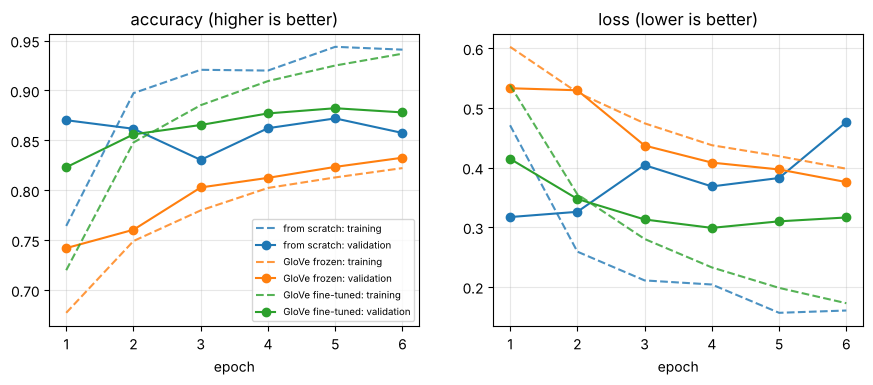

In [7]:
fig = it.plot_history([histories[("from scratch", 42)], histories[("GloVe frozen", 42)], histories[("GloVe fine-tuned", 42)]],
                      ["from scratch", "GloVe frozen", "GloVe fine-tuned"])
save_figure(fig, "02_curves.png")
plt.show()

**What to notice** (seed 42; dashed = training, solid with dots = validation):

- **From scratch (blue):** good immediately (0.87 in epoch 1), then flat or falling; the validation loss *rises* from about 0.32 to 0.48 while the training accuracy climbs to 0.94: early memorising, as in notebook 01.
- **GloVe fine-tuned (green):** it starts lower (0.82 in epoch 1) but keeps improving until epoch 5 (0.88), and its validation loss stays around 0.30 to 0.32 instead of rising. The pretrained start did not make learning *faster* in the first epoch, but the model memorised less.
- **GloVe frozen (orange):** slow and still rising at the end (0.74 in epoch 1, 0.83 in epoch 6, training accuracy only 0.82). With only six epochs it has probably not finished learning, so its result below is partly a statement about our time budget, not only about freezing.

*Figure: accuracy (left) and loss (right) per epoch for the three LSTM variants, seed 42.*

## 4 · Two more reference points

**Bag of words** (from notebook 01) and **VADER**. VADER needs *text*, but Keras only stores word numbers, so we rebuild the text from the
full word list (all 88,000 words, no 10,000-word limit). This text has no capital letters and no punctuation, which VADER normally uses as clues
(for instance "GREAT!!!"), so VADER is somewhat handicapped here. VADER returns a score between -1 and +1; we call a review positive when the score is above 0.

In [8]:
from sklearn.linear_model import LogisticRegression

counting = LogisticRegression(max_iter=1000).fit(it.bag_of_words(x_train), y_train)

start = time.time()
texts, y_test_text = it.full_text_reviews()
assert (y_test_text == y_test).all()                      # same reviews, same order as the numbers
vader_prediction = it.vader_predictions(texts)
print(f"VADER needed no training; it read {len(texts)} reviews in {time.time() - start:.0f} s")
print("example of the rebuilt text:", texts[0][:160], "...")

VADER needed no training; it read 25000 reviews in 38 s
example of the rebuilt text: please give this one a miss kristy swanson and the rest of the cast rendered terrible performances the show is flat flat flat i don't know how michael madison c ...


## 5 · The final grade (test set, used once per model)

All models are now graded on the **same 25,000 test reviews**. (A fixed subset would only be needed if a model were too slow to run on all of them;
none of ours is.)

In [9]:
test_accuracy = {key: model.evaluate(x_test_pad, y_test, batch_size=256, verbose=0)[1] for key, model in models.items()}
bag_accuracy = counting.score(it.bag_of_words(x_test), y_test)
vader_accuracy = float((vader_prediction == y_test).mean())

print(f"{'model':20s} {'seeds':>5s}  {'mean test accuracy':>18s}  {'smallest-largest':>17s}")
summary = {}
for name in ["from scratch", "GloVe frozen", "GloVe fine-tuned"]:
    values = np.array([a for (n, s), a in test_accuracy.items() if n == name])
    summary[name] = values
    print(f"{name:20s} {len(values):5d}  {values.mean():18.4f}  {values.min():.4f}-{values.max():.4f}")
print(f"{'bag of words':20s} {'-':>5s}  {bag_accuracy:18.4f}")
print(f"{'VADER (no training)':20s} {'-':>5s}  {vader_accuracy:18.4f}")

print("\npaired difference per seed, fine-tuned GloVe minus from scratch:",
      [round(test_accuracy[("GloVe fine-tuned", s)] - test_accuracy[("from scratch", s)], 4) for s in (42, 1, 2)])
margin = 1.96 * (0.86 * 0.14 / 25000) ** 0.5
print(f"95 percent margin of a single accuracy measured on 25,000 reviews (binomial): about +-{margin:.4f}")

model                seeds  mean test accuracy   smallest-largest
from scratch             3              0.8625  0.8574-0.8675
GloVe frozen             1              0.8285  0.8285-0.8285
GloVe fine-tuned         3              0.8704  0.8661-0.8738
bag of words             -              0.8572
VADER (no training)      -              0.6984

paired difference per seed, fine-tuned GloVe minus from scratch: [0.0035, 0.0063, 0.014]
95 percent margin of a single accuracy measured on 25,000 reviews (binomial): about +-0.0043


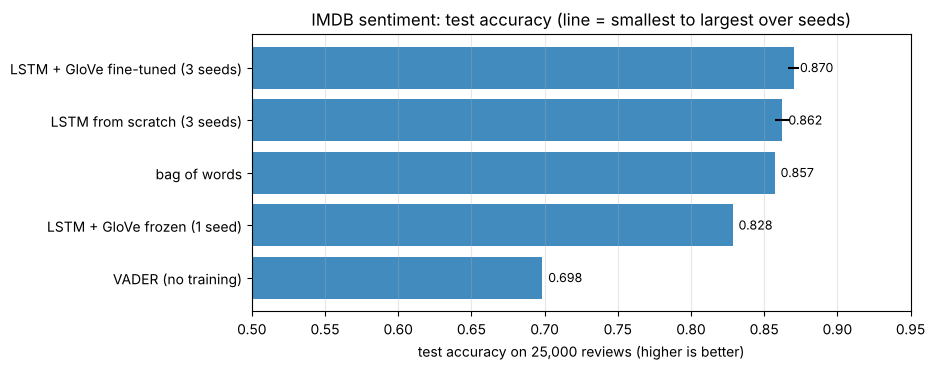

In [10]:
names = ["VADER (no training)", "LSTM + GloVe frozen (1 seed)", "bag of words", "LSTM from scratch (3 seeds)", "LSTM + GloVe fine-tuned (3 seeds)"]
means = [vader_accuracy, summary["GloVe frozen"].mean(), bag_accuracy, summary["from scratch"].mean(), summary["GloVe fine-tuned"].mean()]
lows = [vader_accuracy, summary["GloVe frozen"].min(), bag_accuracy, summary["from scratch"].min(), summary["GloVe fine-tuned"].min()]
highs = [vader_accuracy, summary["GloVe frozen"].max(), bag_accuracy, summary["from scratch"].max(), summary["GloVe fine-tuned"].max()]
fig = it.plot_results(names[::-1], means[::-1], lows[::-1], highs[::-1])
fig.axes[0].set_title("IMDB sentiment: test accuracy (line = smallest to largest over seeds)")
save_figure(fig, "02_results.png")
plt.show()

**What to notice** (all numbers measured on the same 25,000 test reviews):

| Model | Test accuracy |
|---|---|
| LSTM + GloVe fine-tuned (3 seeds) | 0.8704 mean (0.8661 to 0.8738) |
| LSTM from scratch (3 seeds) | 0.8625 mean (0.8574 to 0.8675) |
| bag of words + logistic regression | 0.8572 |
| LSTM + GloVe frozen (1 seed, 6 epochs) | 0.8285 |
| VADER, no training (on rebuilt text) | 0.6984 |

- **Fine-tuned GloVe beats from scratch by about 0.8 points on average**, and it was ahead for every seed (+0.35, +0.63 and +1.40 points). That is a small but consistent gain. The ranges of the two models still overlap a little (0.8661 versus 0.8675) and three seeds are not many, so we call it "a small gain", not a proof. Remember also that the two models differ in size (50 instead of 32 coordinates per word).
- **The simple word-counting baseline (0.8572) is only about one point behind the best LSTM.** The neural models are ahead, but not by much.
- **Frozen GloVe is worse (0.8285)**, probably partly because it had not finished learning after six epochs (see the curves).
- **VADER (0.6984)** is far behind here. It was built for other kinds of text and our rebuilt text lacks the punctuation and capital letters it uses; this number says little about VADER in general.
- A single accuracy measured on 25,000 reviews has a statistical margin of about 0.4 points, which is about half of the gain we found: another reason not to over-read it.
- **Not tested:** a pretrained Transformer (the host that serves such models was blocked in this environment, see section 1). We do not know how it would compare.

*Figure: test accuracy of the compared models; the thin line spans the smallest to the largest value over seeds, and the bars start at 0.5 (coin-flip level), not at zero.*

### Check yourself

1. Why do the three seeds of the same model give different test accuracies?
2. VADER was never trained on movie reviews. Does a score of about 0.7 mean it is a bad tool?

<details>
<summary>Answers</summary>


1. The seed changes the random starting numbers of the layers (and the order of the data in each epoch). Training then follows a slightly different path and ends in a slightly different place.
2. Not necessarily. It means it is a poor fit *here*: it was made for short social-media text, it needs punctuation and capital letters which our rebuilt text lacks, and it has no idea about movie-specific language. A tool should be judged on the task it was built for as well.

</details>

## 6 · Common mistakes

- **Comparing models that were given different data or different tests.** Here every model sees the same 20,000 training reviews (VADER none) and the same 25,000 test reviews.
- **Claiming a win from one run.** Three seeds show that the difference between the two LSTM versions is small compared with the run-to-run spread; with one seed each, either order could have appeared.
- **Calling any reuse "a pretrained language model".** Word vectors are a small, static kind of pretrained knowledge; a Transformer is something else, and we could not test it here.
- **Forgetting licences and terms of pretrained resources.** GloVe's licence as listed by the distribution we used (gensim-data) is the Public Domain Dedication and License; we could not open the original page to double-check it.
- **Freezing without thinking.** Frozen vectors keep general knowledge but cannot adapt to the task ("unpredictable" can be a compliment in a film review and an insult elsewhere).

## 7 · Recap

- Pretrained word vectors let a model start with knowledge from billions of words; fine-tuning them lets it adapt that knowledge to the task.
- In our test the benefit was small and consistent in sign over three seeds, and everything neural was only a little ahead of simply counting words.
- An honest comparison uses the same data and test set, several seeds, and says what could not be tested (here: a pretrained Transformer).

**Next:** notebook 03 opens the model: which words push a review towards "positive" or "negative"? (word-level explanations)